In [1]:
import os
import re
import datetime as dt
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, Markdown
from rapidfuzz import fuzz
from tqdm.auto import tqdm

try:  # optional: only needed if coverage counts are missing and an API key is available
    from dotenv import load_dotenv
except ImportError:
    load_dotenv = None

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.max_colwidth", 110, "display.width", 200, "display.max_columns", 40)

In [2]:
# ---- Paths (relative to analysis/tenant-headlines/) ----
DATA_DIR = Path("../../data/headlines")
RAW_DIR = DATA_DIR / "raw"                      # supplied (hierarchy-deduplicated) headline files
COVERAGE_DIR = DATA_DIR / "coverage"            # indexed-volume tables
DOWNLOAD_DIR = DATA_DIR                         # where the original MediaCloud downloads live
TENANT_DOWNLOAD = DOWNLOAD_DIR / "tenants_title.csv"
LANDLORD_DOWNLOAD = DOWNLOAD_DIR / "landlords_title.csv"
PREPARED_PATH = DATA_DIR / "prepared" / "headlines_prepared.csv"
COVERAGE_FILE = COVERAGE_DIR / "coverage_per_source_per_year.csv"

# ---- Study window and reference numbers ----
YEARS = list(range(2015, 2026))
EXPECTED_SUPPLIED = {"tenant": 4629, "landlord": 2456, "shared_ids": 864}   # as described in the brief; verified below
LEGACY_REPORTED = {"tenant_non_duplicate": 4198, "landlord_non_duplicate": 2186}  # printed by the archived notebooks

# ---- Legacy build settings (used only to verify the downloads reproduce the supplied files) ----
LEGACY_MIN_COVERAGE = 100      # >= this many indexed English stories per source-year
DEDUP_HIERARCHY = [
    "cbc.ca", "ctvnews.ca", "globalnews.ca", "thestar.com", "theglobeandmail.com", "nationalpost.com",
    "nationalobserver.com", "vancouversun.com", "ottawacitizen.com", "montrealgazette.com",
    "edmontonjournal.com", "calgaryherald.com", "winnipegfreepress.com", "timescolonist.com", "thespec.com",
    "lfpress.com", "therecord.com", "torontosun.com", "calgarysun.com", "edmontonsun.com", "winnipegsun.com",
    "thewhig.com", "intelligencer.ca", "brandonsun.com", "brantfordexpositor.ca", "niagarafallsreview.ca",
    "wellandtribune.ca", "lethbridgeherald.com", "reddeeradvocate.com", "kelownadailycourier.ca",
    "pentictonherald.ca", "abbynews.com", "medicinehatnews.com", "trailtimes.ca", "kimberleybulletin.com",
    "dailyheraldtribune.com", "nugget.ca", "tj.news", "standard-freeholder.com", "woodstocksentinelreview.com",
    "bclocalnews.com", "canadianbusiness.com", "moneysense.ca", "canoe.com", "nationalnewswatch.com",
    "canadanews.net", "canadastandard.com",
]

# ---- Story-family matching (adjustable) ----
EXACT_WINDOW_DAYS = 3          # identical normalized titles link only if published within this many days
NEAR_WINDOW_DAYS = 3           # near-identical titles link only within this window
NEAR_SIMILARITY = 90           # rapidfuzz ratio (0-100) on normalized titles
NEAR_MIN_CHARS = 25            # very short titles are never fuzzy-matched
BORDERLINE_MARGIN = 6          # candidate pairs this far below the threshold are shown for review

# ---- Coverage diagnostics (adjustable) ----
SPARSE_THRESHOLD = 500         # indexed English stories per source-year below this = "sparse"
JUMP_FACTOR = 3.0              # year-over-year change at least this large = "coverage break"
JUMP_MIN_BASE = 500            # both years must exceed this for a jump to be assessed
MEDIACLOUD_COLLECTION_ID = 34411583   # Canada - National
API_KEY_ENV_VAR = "MEDIACLOUD_API_KEY"

# ---- Display ----
SEED = 42
COLORS = {"tenant": "#2a78d6", "landlord": "#eb6834", "both": "#6b6a66"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

# 01 · Prepare and audit

**Goal of this notebook.** Turn the supplied headline files into one clean, well-documented article table that the next two notebooks can analyse, and be honest about what that table can and cannot tell us.

What happens here:

1. Load the two supplied headline files and check them against the numbers we were told to expect.
2. Check whether the *original downloads* still exist, so we can recover the copies of syndicated stories that the earlier hierarchy-based de-duplication threw away.
3. Combine everything into one article table, keeping **which search found each headline** separate from **which group the headline actually mentions**.
4. Audit missing values, overlap, residential relevance, outlets and years.
5. Group copies of the same story into conservative **story families**.
6. Validate the coverage (indexed-volume) table, flag sparse years and abrupt breaks, and make requests only if counts are genuinely missing.
7. Reconcile the old notebooks' statistics with the current files, then save one prepared dataset.

A note on vocabulary used throughout: a **headline row** is one published copy at one outlet; a **story family** is a set of copies we believe are the same story (syndicated or lightly edited); the **tenant search** and **landlord search** are the title keyword searches that produced the raw files.

## 1. Load the supplied files and verify the headline numbers

In [3]:
supplied_t = pd.read_csv(RAW_DIR / "headlines_tenant.csv")
supplied_l = pd.read_csv(RAW_DIR / "headlines_landlord.csv")

shared_ids = set(supplied_t["id"]) & set(supplied_l["id"])
check = pd.DataFrame({
    "expected": [EXPECTED_SUPPLIED["tenant"], EXPECTED_SUPPLIED["landlord"], EXPECTED_SUPPLIED["shared_ids"]],
    "found": [len(supplied_t), len(supplied_l), len(shared_ids)],
}, index=["tenant rows", "landlord rows", "shared IDs"])
check["matches"] = check["expected"] == check["found"]
display(check)
print("Columns:", list(supplied_t.columns))
print("Rows flagged is_duplicate=True that are still present:",
      f"tenant {int(supplied_t['is_duplicate'].sum()):,}, landlord {int(supplied_l['is_duplicate'].sum()):,}")

,expected,found,matches
tenant rows,4629,4629,True
landlord rows,2456,2456,True
shared IDs,864,864,True


Columns: ['id', 'title', 'url', 'publish_date', 'language', 'media_name', 'media_url', 'year', 'is_duplicate']
Rows flagged is_duplicate=True that are still present: tenant 431, landlord 270


The `is_duplicate` flag was computed **before** hierarchy-based de-duplication, so a row that still carries `is_duplicate=True` is the *surviving* copy of a syndicated story, not an extra copy. The archived exploratory notebooks dropped these rows (`~is_duplicate`), which silently deleted every syndicated story whose only remaining copy carried the flag. This notebook never filters on that flag; it keeps it only as provenance.

## 2. Are the original downloads available?

The supplied files are the *output* of a build step (`build_headline_dataset`): English-only, source-years with at least 100 indexed stories, then one copy per identical title+date chosen by an outlet hierarchy. If the raw MediaCloud downloads are still in the project, we can re-run those exact steps, **prove** that they reproduce the supplied files, and then use the downloads to recover the publication copies that the hierarchy discarded. No new headline data is requested.

In [4]:
coverage = pd.read_csv(COVERAGE_FILE)
downloads_available = TENANT_DOWNLOAD.exists() and LANDLORD_DOWNLOAD.exists()
print("Original downloads found:", downloads_available)


def legacy_pipeline(raw, valid_pairs):
    """Re-run the legacy filters on a raw download: English, coverage threshold, title+date hierarchy de-dup."""
    d = raw.copy()
    d["year"] = pd.to_datetime(d["publish_date"]).dt.year
    d = d[d["language"].isin(["en"]) | d["language"].isna()]
    d = d[[(s, y) in valid_pairs for s, y in zip(d["media_name"], d["year"])]]
    rank = {s: i for i, s in enumerate(DEDUP_HIERARCHY)}
    d = d.assign(_rank=d["media_name"].map(rank).fillna(len(DEDUP_HIERARCHY)),
                 _key=d["title"].fillna("").str.strip().str.lower() + "|||" + d["publish_date"].astype(str))
    kept = d.loc[d.groupby("_key")["_rank"].idxmin()]
    return d.drop(columns=["_rank", "_key"]), kept


if downloads_available:
    dl_t = pd.read_csv(TENANT_DOWNLOAD)
    dl_l = pd.read_csv(LANDLORD_DOWNLOAD)
    valid_pairs = {(r.source, int(r.year)) for r in coverage.itertuples() if r.matching_stories >= LEGACY_MIN_COVERAGE}
    recon = []
    filtered = {}
    for name, dl, sup in [("tenant", dl_t, supplied_t), ("landlord", dl_l, supplied_l)]:
        filt, kept = legacy_pipeline(dl, valid_pairs)
        filtered[name] = filt
        recon.append({
            "search": name, "raw download rows": len(dl), "non-English dropped": int((~(dl["language"].isin(["en"]) | dl["language"].isna())).sum()),
            "dropped by coverage threshold": int(len(dl) - len(filt)) - int((~(dl["language"].isin(["en"]) | dl["language"].isna())).sum()),
            "publication copies kept": len(filt), "hierarchy representatives": len(kept),
            "supplied rows": len(sup), "reproduces supplied IDs exactly": set(kept["id"]) == set(sup["id"]),
        })
    display(pd.DataFrame(recon).set_index("search"))
    reproduced = all(r["reproduces supplied IDs exactly"] for r in recon)
else:
    reproduced = False
    print("Original downloads are not in the project; supplied files cannot reconstruct the publication distribution.")

HAS_PUBLICATION_COPIES = bool(downloads_available and reproduced)
print("\nPublication copies recoverable:", HAS_PUBLICATION_COPIES)

Original downloads found: True


,raw download rows,non-English dropped,dropped by coverage threshold,publication copies kept,hierarchy representatives,supplied rows,reproduces supplied IDs exactly
search,,,,,,,
tenant,5684,0,1,5683,4629,4629,True
landlord,3140,0,0,3140,2456,2456,True



Publication copies recoverable: True


**How to read the table above.** If `reproduces supplied IDs exactly` is `True` for both searches, the downloads fully explain the supplied files, so the discarded copies are recoverable and *every* publication copy (before hierarchy de-duplication) can be used for outlet-level analysis. If it is `False`, or the downloads are missing, the code below falls back to the supplied rows only and the outlet-level view is marked unavailable, because hierarchy-selected representatives cannot reconstruct how often each outlet actually ran a story.

One caveat that remains either way: the downloads are MediaCloud's *indexed* content for the "Canada - National" collection (English-only, outlets in that collection only). They are not a census of Canadian headlines.

## 3. One article table, with search membership kept separate from actual mentions

Each unique `id` becomes one row. Four provenance flags are kept:

* `in_search_tenant` / `in_search_landlord` — did the original keyword search return it? (Needs the downloads.)
* `in_supplied_tenant` / `in_supplied_landlord` — is it one of the hierarchy-selected rows in the supplied files?

The *actual* mentions are determined from the headline text in section 5, and are a separate set of columns.

In [5]:
FILE_COLS = ["id", "title", "url", "publish_date", "language", "media_name"]


def build_article_table():
    if HAS_PUBLICATION_COPIES:
        base = pd.concat([filtered["tenant"][FILE_COLS], filtered["landlord"][FILE_COLS]]).drop_duplicates("id")
        in_t, in_l = set(filtered["tenant"]["id"]), set(filtered["landlord"]["id"])
    else:
        base = pd.concat([supplied_t[FILE_COLS], supplied_l[FILE_COLS]]).drop_duplicates("id")
        in_t, in_l = set(supplied_t["id"]), set(supplied_l["id"])
    art = base.reset_index(drop=True)
    art["in_search_tenant"] = art["id"].isin(in_t)
    art["in_search_landlord"] = art["id"].isin(in_l)
    sup_all = pd.concat([supplied_t.assign(_src="t"), supplied_l.assign(_src="l")])
    art["in_supplied_tenant"] = art["id"].isin(set(supplied_t["id"]))
    art["in_supplied_landlord"] = art["id"].isin(set(supplied_l["id"]))
    art["selected_by_hierarchy"] = art["in_supplied_tenant"] | art["in_supplied_landlord"]
    legacy_flag = sup_all.groupby("id")["is_duplicate"].max()
    art["legacy_is_duplicate_flag"] = art["id"].map(legacy_flag)       # NaN for copies the hierarchy discarded
    art["publish_dt"] = pd.to_datetime(art["publish_date"], errors="coerce")
    art["year"] = art["publish_dt"].dt.year
    art["publication_copy_source"] = "raw_download" if HAS_PUBLICATION_COPIES else "supplied_representatives_only"
    return art


articles = build_article_table()
print(f"{len(articles):,} unique headline rows "
      f"({int(articles['selected_by_hierarchy'].sum()):,} are hierarchy-selected representatives; "
      f"{int((~articles['selected_by_hierarchy']).sum()):,} are recovered publication copies)")

7,726 unique headline rows (6,221 are hierarchy-selected representatives; 1,505 are recovered publication copies)


## 4. Audit: missing values, repeated IDs and URLs, cross-file overlap

In [6]:
def pct(x, n):
    return f"{100 * x / n:.1f}%"


miss = pd.DataFrame({
    "missing": [int(articles[c].isna().sum() + (articles[c].astype(str).str.strip() == "").sum()) for c in ["id", "title", "url", "publish_date", "language", "media_name"]],
}, index=["id", "title", "url", "publish_date", "language", "media_name"])
miss["unparseable date"] = [0, 0, 0, int(articles["publish_dt"].isna().sum()), 0, 0]
display(miss.T)
print("Language values:", articles["language"].value_counts(dropna=False).to_dict())
print("Dates outside study window:", int((~articles["year"].between(YEARS[0], YEARS[-1])).sum()))
print("year column in supplied files agrees with publish_date:",
      bool((pd.concat([supplied_t, supplied_l]).assign(y=lambda d: pd.to_datetime(d["publish_date"]).dt.year).eval("y == year")).all()))

print("\nRepeated identifiers")
print("  repeated IDs within each supplied file:", int(supplied_t["id"].duplicated().sum()), "/", int(supplied_l["id"].duplicated().sum()))
print("  repeated URLs within the article table:", int(articles["url"].duplicated().sum()))
print("  repeated IDs across supplied files (the 'shared' headlines):", len(shared_ids))

overlap = (articles.groupby(["in_search_tenant", "in_search_landlord"]).size()
           .rename("rows").reset_index()
           .assign(group=lambda d: np.select([d.in_search_tenant & d.in_search_landlord, d.in_search_tenant], ["both searches", "tenant search only"], "landlord search only")))
display(overlap[["group", "rows"]])
sel = articles[articles["selected_by_hierarchy"]]
print(f"Among hierarchy-selected rows: tenant-only {int((sel.in_supplied_tenant & ~sel.in_supplied_landlord).sum()):,}, "
      f"landlord-only {int((~sel.in_supplied_tenant & sel.in_supplied_landlord).sum()):,}, both {int((sel.in_supplied_tenant & sel.in_supplied_landlord).sum()):,}")

,id,title,url,publish_date,language,media_name
missing,0,0,0,0,0,0
unparseable date,0,0,0,0,0,0


Language values: {'en': 7726}
Dates outside study window: 0
year column in supplied files agrees with publish_date: True

Repeated identifiers
  repeated IDs within each supplied file: 0 / 0
  repeated URLs within the article table: 0
  repeated IDs across supplied files (the 'shared' headlines): 864


,group,rows
0,landlord search only,2043
1,tenant search only,4586
2,both searches,1097


Among hierarchy-selected rows: tenant-only 3,765, landlord-only 1,592, both 864


Read the tables above: any non-zero count of missing values, unparseable dates, repeated IDs or repeated URLs would need attention before analysis. The tenant/landlord overlap is large because many headlines contain both words ("landlord", "tenant"), so search membership alone cannot say who a headline is *about*; the next step reads the headline itself.

## 5. Who is actually mentioned?

The searches matched title keywords, so membership and mention should agree most of the time, but there are two traps:

1. **Institution names and the legal concept of "tenancy".** "Landlord and Tenant Board" (Ontario's tribunal) and "Residential Tenancies Act" contain the group words without portraying either group, and "tenancy" on its own ("tenancy law", "tenancy dispute") names a legal arrangement rather than a person. Institution names are removed before looking for mentions, "tenancy" does not count as a tenant mention, and headlines whose only hits are of this kind are labelled `non_person_term_only` rather than counted as tenant/landlord portrayals.
2. **Search quirks.** Hyphenated or punctuated forms can be missed by one search; the crosstab below shows how often.

Person-mention terms are tenant/tenants/renter/renters and landlord/landlords (the searches also used "tenancy", which is tracked but does not count as a mention of people). Other terms for the same roles ("property owner", "housing provider") are outside the sampling frame and are counted below only to show how much we are not seeing.

In [7]:
TENANT_RE = re.compile(r"\b(?:tenants?|renters?)\b", re.I)
TENANCY_RE = re.compile(r"\b(?:tenancy|tenancies)\b", re.I)
LANDLORD_RE = re.compile(r"\blandlords?\b", re.I)
INSTITUTION_RE = re.compile(
    r"\b(?:landlords?\s*(?:and|&|/|-|–)?\s*tenants?\s+(?:board|act|tribunal|branch|relations(?:\s+act)?|advisory\s+board)"
    r"|residential\s+tenanc(?:y|ies)\s+(?:act|board|branch|commission|tribunal|office|regulation|dispute\s+resolution)"
    r"|tenant\s+protection\s+act"
    r"|protecting\s+tenants\s+and\s+strengthening\s+community\s+housing\s+act"
    r"|rental\s+housing\s+(?:tribunal|enforcement\s+unit))\b", re.I)
OUT_OF_FRAME_RE = re.compile(r"\b(?:property\s+owners?|housing\s+providers?|rental\s+providers?|property\s+managers?|slumlords?|lessors?|lessees?|occupants?)\b", re.I)


def classify_mentions(title):
    stripped = INSTITUTION_RE.sub(" ", title)
    return (bool(TENANT_RE.search(stripped)), bool(LANDLORD_RE.search(stripped)),
            bool(INSTITUTION_RE.search(title)),
            bool(INSTITUTION_RE.search(title) or TENANCY_RE.search(title)))


m = np.array([classify_mentions(t) for t in articles["title"]])
articles["mentions_tenant"], articles["mentions_landlord"] = m[:, 0], m[:, 1]
articles["institution_name_in_title"] = m[:, 2]
articles["mention_group"] = np.select(
    [m[:, 0] & m[:, 1], m[:, 0], m[:, 1], m[:, 3]], ["both", "tenant", "landlord", "non_person_term_only"], "none")

print("Actual mentions (headline text):")
display(articles["mention_group"].value_counts().rename("rows").to_frame())
print("Search membership vs actual mention:")
display(pd.crosstab([articles["in_search_tenant"].map({True: "tenant search", False: "-"}),
                     articles["in_search_landlord"].map({True: "landlord search", False: "-"})],
                    articles["mention_group"], margins=True))
n_oof = int(articles["title"].str.contains(OUT_OF_FRAME_RE).sum())
print(f"Headlines also containing other role words (property owner, housing provider, slumlord...): {n_oof:,} ({pct(n_oof, len(articles))}); "
      "these are outside the keyword frame and are not analysed as group mentions.")
print("\nExamples labelled non_person_term_only (institution name or the word 'tenancy' only):")
for t in articles.loc[articles["mention_group"] == "non_person_term_only", "title"].sample(8, random_state=SEED):
    print("  -", t)

Actual mentions (headline text):


,rows
mention_group,
tenant,4476
landlord,2038
both,1073
non_person_term_only,139


Search membership vs actual mention:


mention_group                        both  landlord  non_person_term_only  tenant   All
in_search_tenant in_search_landlord                                                    
-                landlord search       16      2027                     0       0  2043
tenant search    -                     34         0                    90    4462  4586
                 landlord search     1023        11                    49      14  1097
All                                  1073      2038                   139    4476  7726

Headlines also containing other role words (property owner, housing provider, slumlord...): 30 (0.4%); these are outside the keyword frame and are not analysed as group mentions.

Examples labelled non_person_term_only (institution name or the word 'tenancy' only):
  - The kids seeing the world before going blind + delays at the Landlord and Tenant Board
  - The Landlord and Tenant Board must resume in-person hearings
  - B.C. changes tenancy regulations to limit rent increases to match area rates
  - St. Catharines woman’s fate in hands of Landlord and Tenant Board
  - No adjudicators for Landlord Tenant Board; disputes resolved over the phone
  - West Ham opens Olympic Stadium tenancy with victory
  - New enforcement unit adds 'teeth' to B.C. tenancy laws
  - Landlord Tenant Board backlog: Why Ontarians are waiting months for resolutions


## 6. Relevance to residential rental housing

"Tenant" and "landlord" are not always about homes: commercial leases (malls, offices, restaurants), and a handful of other uses, are mixed in. A simple cue-based classifier labels each headline; it is deliberately transparent so it can be inspected and changed.

* `residential` — residential cues (housing, apartment, eviction, rent increase, Landlord and Tenant Board ...) and no commercial cues
* `commercial` — commercial cues (commercial, retail, office, restaurant, mall, anchor tenant, small business ...) and no residential cues
* `mixed_cues` — both kinds of cues
* `unclear` — neither; most are probably residential, since the plain words "tenant" and "landlord" overwhelmingly refer to housing in news headlines

The main analysis keeps all of them (no aggressive exclusion). Notebook 3 re-runs key comparisons after dropping non-residential headlines.

In [8]:
RESIDENTIAL_CUES = re.compile(
    r"\b(?:housing|apartments?|condos?|condominiums?|evict\w*|renovict\w*|demovict\w*|ltb|rtb|residential\s+tenanc\w*|"
    r"rent\s+(?:increases?|hikes?|control|cap|freeze|relief|strike|bank|supplements?|subsid\w*|prices?)|rents\b|"
    r"rental\s+(?:housing|market|units?|apartments?|crisis|homes?|accommodations?|supply|vacanc\w*|properties|property|listings?|registry|licen\w+)|"
    r"mou?ld|bed\s?bugs?|homeless\w*|basements?|roommates?|bedrooms?|public\s+housing|social\s+housing|"
    r"landlord\s+and\s+tenant\s+board|renters?|affordab\w+|secondary\s+suites?|student\s+(?:housing|renters?)|"
    r"low-income|shelters?|cockroach\w*|rent[- ]to[- ]own|move[- ]out|leases?|subletting|sublet|rent\w*|"
    r"homes?|houses?|duplex|townhouse|units?|buildings?|tenant\s+insurance|utilities|heat|deposit|security\s+deposit|dorm\w*|residen\w+)\b", re.I)
COMMERCIAL_CUES = re.compile(
    r"\b(?:commercial|retail\w*|office\s+(?:space|tower|building|tenants?)|offices?|restaurants?|storefronts?|shopping|malls?|"
    r"anchor\s+tenants?|small\s+business\w*|businesses|business\s+owners?|warehouses?|industrial|brewery|pot\s+shops?|"
    r"cannabis\s+(?:store|shop|dispensar\w+)|nightclub|bars?|cafes?|hq|headquarters|cecra|storage|retailers?|"
    r"tenant\s+mix|leasing\s+deal|occupancy\s+rate|real\s+estate\s+investment\s+trust|reit|"
    r"hudson.s\s+bay|target\s+canada|sears|walmart)\b", re.I)


def relevance_label(title):
    res, com = bool(RESIDENTIAL_CUES.search(title)), bool(COMMERCIAL_CUES.search(title))
    return "mixed_cues" if (res and com) else "residential" if res else "commercial" if com else "unclear"


articles["relevance"] = articles["title"].map(relevance_label)
rel = (articles[articles["mention_group"] != "non_person_term_only"]
       .groupby(["relevance", "mention_group"]).size().unstack(fill_value=0))
rel["total"] = rel.sum(axis=1)
rel["share"] = (100 * rel["total"] / rel["total"].sum()).round(1)
display(rel)

rng = np.random.default_rng(SEED)
for label in ["commercial", "mixed_cues", "unclear"]:
    pool = articles[articles["relevance"] == label]["title"].tolist()
    print(f"\nRandom '{label}' headlines (n={len(pool):,}):")
    for t in rng.choice(pool, size=min(8, len(pool)), replace=False):
        print("  -", t[:120])

mention_group,both,landlord,tenant,total,share
relevance,,,,,
commercial,21,126,107,254,3.3
mixed_cues,17,165,47,229,3.0
residential,607,888,3355,4850,63.9
unclear,428,859,967,2254,29.7



Random 'commercial' headlines (n=256):
  - SmartREIT and Mitchell Goldhar announce FM Global as a New Tenant in its Class A Office Tower at Vaughan Metropolitan Ce
  - Deadly warehouse fire suspect says landlord also responsible
  - Court documents reveal Hudson’s Bay owes $950 million to landlords, fashion brands, banks and government
  - Landlords say Ruby Liu’s plan for Bay properties ‘defies commercial common sense’
  - 'Don't think it's fair': Speculation tax exemption created for some B.C. commercial property tenants
  - RioCan REIT reports $145.3M net income in Q2 as tenants reopen after lockdowns
  - First tenant named for River Landing office tower
  - Calgary landlord tackles rising commercial vacancy rates with innovative ideas

Random 'mixed_cues' headlines (n=230):
  - Hudson’s Bay asks court to force landlords to let B.C. billionaire take over leases
  - B.C. offers small business eviction protection, urges landlord participation
  - B.C. mall owner lays out plan for Bay

Judge the classifier from the samples above: `commercial` headlines should be about malls, offices, retail or restaurants; `mixed_cues` headlines carry both kinds of cue and are mostly ambiguous or commercial stories borrowing housing words; `unclear` headlines carry neither, and most are expected to be ordinary housing stories without a keyword. The classifier is a screening tool, not ground truth; its main job is to let Notebook 3 test whether results survive removing headlines likely to be about commercial tenancy.

## 7. Counts by source and year; dominant outlets

Publication copies (all recovered rows) by year and actual mention:


mention_group,both,landlord,tenant,all copies
year,,,,
2015,36,115,207,358
2016,58,123,236,417
2017,98,198,407,703
2018,137,200,425,762
2019,76,187,484,747
2020,195,346,512,1053
2021,72,141,388,601
2022,72,120,383,575
2023,81,124,377,582


70 outlets. Top 5 share 53.1%; top 10 share 67.4%; 30 outlets have fewer than 20 headlines.


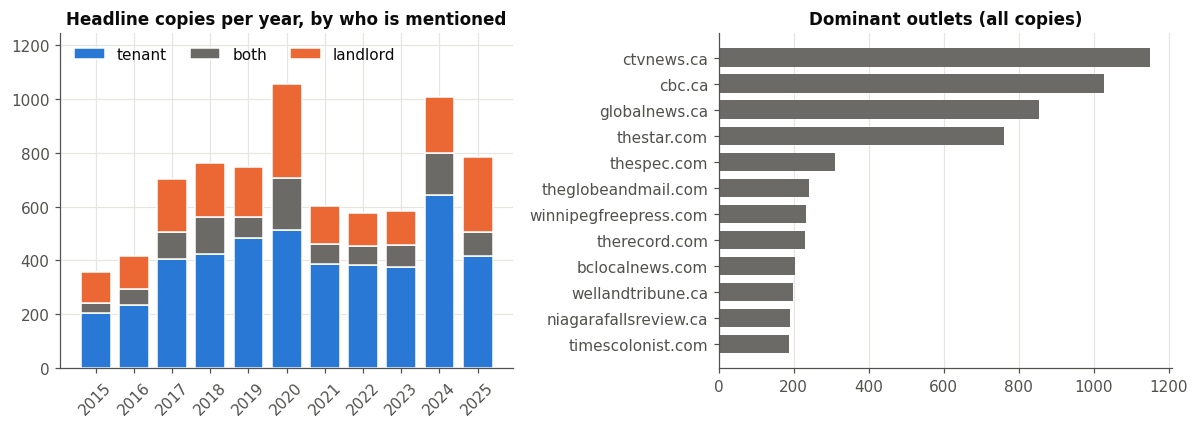

In [9]:
distinct_view = articles[articles["selected_by_hierarchy"] & (articles["mention_group"] != "non_person_term_only")]
by_year = (articles[articles["mention_group"].isin(["tenant", "landlord", "both"])]
           .groupby(["year", "mention_group"]).size().unstack(fill_value=0).reindex(YEARS, fill_value=0))
by_year["all copies"] = by_year.sum(axis=1)
print("Publication copies (all recovered rows) by year and actual mention:")
display(by_year)

src_counts = articles.groupby("media_name").size().sort_values(ascending=False)
top = src_counts.head(12)
print(f"{articles['media_name'].nunique()} outlets. Top 5 share {pct(src_counts.head(5).sum(), len(articles))}; "
      f"top 10 share {pct(src_counts.head(10).sum(), len(articles))}; "
      f"{int((src_counts < 20).sum())} outlets have fewer than 20 headlines.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
bottom = np.zeros(len(YEARS))
for g in ["tenant", "both", "landlord"]:
    ax.bar(YEARS, by_year[g].values, bottom=bottom, color=COLORS[g], label=g, width=0.78, edgecolor="white", linewidth=1)
    bottom += by_year[g].values
ax.set_title("Headline copies per year, by who is mentioned")
ax.set_xticks(YEARS); ax.tick_params(axis="x", rotation=45)
ax.set_ylim(0, by_year["all copies"].max() * 1.18); ax.legend(title=None, ncol=3, loc="upper left", columnspacing=1.5)
ax = axes[1]
ax.barh(top.index[::-1], top.values[::-1], color=COLORS["both"], height=0.7)
ax.set_title("Dominant outlets (all copies)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

The corpus is concentrated in a handful of national and large regional outlets, and the yearly counts are not flat (compare the 2020 and 2024 bars with their neighbours). Both facts matter for Notebook 3: year and outlet composition will be adjusted for, and the largest outlets are dropped one at a time as a robustness check. Whether the year-to-year swings reflect publishing or indexing is examined next, with the coverage table.

## 8. Story families

Syndicated stories appear under the same headline at many outlets; edited versions differ by a word or two. We group copies into **families** so that one story counts once in the distinct-story analysis.

Two levels, both adjustable in the constants cell:

* **Exact family** — identical normalized title (lower-case, punctuation and some outlet suffixes removed) published within `EXACT_WINDOW_DAYS` days of each other. Titles are *not* merged across long gaps: identical headlines months apart are usually recurring items, not one story.
* **Near family** (the main distinct-story definition) — exact families plus pairs of titles with a similarity of at least `NEAR_SIMILARITY` within `NEAR_WINDOW_DAYS` days, subject to guards so that **meaningful wording differences are never merged away**: the sequence of group words (tenant vs landlord, in order), every number, and every negation must be identical. "Landlord sues tenant" and "Tenant sues landlord" are therefore different families even though they are character-for-character similar.

Discussing the same *issue* is never enough to merge; only near-identical wording of the same headline is.

In [10]:
def normalize_title(t):
    t = unicodedata.normalize("NFKC", t).lower()
    t = t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    t = re.sub(r"\s*[|–—-]\s*(cbc news|cbc|ctv news|global news|the globe and mail|toronto star|national post)\s*$", "", t)
    t = re.sub(r"n't\b", " not", t)
    t = re.sub(r"[^\w$%\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


NEGATIONS = {"no", "not", "never", "without", "non", "cannot"}


def key_sequence(norm):
    seq = []
    for tok in norm.split():
        if re.fullmatch(r"tenants?|renters?|tenancy|tenancies", tok):
            seq.append("T")
        elif re.fullmatch(r"landlords?", tok):
            seq.append("L")
        elif re.search(r"\d", tok):
            seq.append(tok)
        elif tok in NEGATIONS:
            seq.append("NOT")
    return tuple(seq)


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[max(ra, rb)] = min(ra, rb)


def build_families(df):
    d = df.sort_values(["publish_dt", "id"]).reset_index(drop=True)
    norm = d["title"].map(normalize_title).tolist()
    keys = [key_sequence(n) for n in norm]
    days = d["publish_dt"].values.astype("datetime64[D]").astype(int)
    n = len(d)

    exact_edges = []
    for _, idx in pd.Series(range(n)).groupby(pd.Series(norm)):
        idx = list(idx)
        for a, b in zip(idx, idx[1:]):
            if days[b] - days[a] <= EXACT_WINDOW_DAYS:
                exact_edges.append((a, b))

    pair_cache, near_edges, candidates = {}, [], []
    floor = NEAR_SIMILARITY - BORDERLINE_MARGIN
    for i in tqdm(range(n), desc="near-duplicate candidates"):
        j = i + 1
        while j < n and days[j] - days[i] <= max(NEAR_WINDOW_DAYS, EXACT_WINDOW_DAYS):
            if norm[i] != norm[j] and len(norm[i]) >= NEAR_MIN_CHARS and len(norm[j]) >= NEAR_MIN_CHARS \
                    and days[j] - days[i] <= NEAR_WINDOW_DAYS:
                pk = (norm[i], norm[j])
                if pk not in pair_cache:
                    pair_cache[pk] = fuzz.ratio(norm[i], norm[j])
                s = pair_cache[pk]
                if s >= floor:
                    guard = keys[i] == keys[j]
                    accepted = bool(s >= NEAR_SIMILARITY and guard)
                    candidates.append({"score": s, "accepted": accepted, "blocked_by_guard": bool(s >= NEAR_SIMILARITY and not guard),
                                       "title_a": d["title"][i], "title_b": d["title"][j], "days_apart": int(days[j] - days[i])})
                    if accepted:
                        near_edges.append((i, j))
            j += 1

    def labels(edges):
        uf = UnionFind(n)
        for a, b in edges:
            uf.union(a, b)
        roots = np.array([uf.find(i) for i in range(n)])
        # stable family id = smallest member id (independent of row order and representative choice)
        member_min = pd.Series(d["id"].values).groupby(roots).transform("min")
        return ("fam_" + member_min.str[:10]).values

    d["family_id_exact"] = labels(exact_edges)
    d["family_id_near"] = labels(exact_edges + near_edges)
    d["title_norm"] = norm
    return d, pd.DataFrame(candidates).drop_duplicates(["title_a", "title_b"])


rank = {s: i for i, s in enumerate(DEDUP_HIERARCHY)}
articles, candidates = build_families(articles)
articles["_rank"] = articles["media_name"].map(rank).fillna(len(DEDUP_HIERARCHY))


def mark_representative(df, fam_col):
    """One representative per family: hierarchy-selected first, then outlet rank, earliest date, id (deterministic)."""
    order = df.assign(_sel=~df["selected_by_hierarchy"]).sort_values([fam_col, "_sel", "_rank", "publish_dt", "id"])
    rep_ids = order.groupby(fam_col).head(1)["id"]
    return df["id"].isin(set(rep_ids))


for level in ["exact", "near"]:
    col = f"family_id_{level}"
    articles[f"is_rep_{level}"] = mark_representative(articles, col)
    articles[f"family_n_copies_{level}"] = articles.groupby(col)["id"].transform("size")
articles["family_n_outlets_near"] = articles.groupby("family_id_near")["media_name"].transform("nunique")
for g in ["tenant", "landlord"]:
    articles[f"family_in_search_{g}"] = articles.groupby("family_id_near")[f"in_search_{g}"].transform("max")

mentioned = articles["mention_group"].isin(["tenant", "landlord", "both"])
summary = pd.DataFrame({
    "rows (publication copies)": [len(articles)],
    "exact families": [articles["family_id_exact"].nunique()],
    "near families": [articles["family_id_near"].nunique()],
    "near families with a group mention": [articles.loc[mentioned, "family_id_near"].nunique()],
    "families with 2+ copies": [int((articles.drop_duplicates("family_id_near")["family_n_copies_near"] > 1).sum())],
    "largest family (copies)": [int(articles["family_n_copies_near"].max())],
})
display(summary.T.rename(columns={0: "n"}))

near-duplicate candidates:   0%|          | 0/7726 [00:00<?, ?it/s]

,n
rows (publication copies),7726
exact families,6121
near families,6039
near families with a group mention,5939
families with 2+ copies,665
largest family (copies),14


### Inspecting borderline matches

Below: (a) pairs accepted by the near rule but not identical (these are the wording variants we chose to merge); (b) pairs just under the threshold, which stay separate; (c) pairs that scored high but were **blocked by the guard** because a group word, number or negation differed. All three should look like what we intended: merged = same headline lightly edited; separate = genuinely different wording.

In [11]:
cand = candidates.sort_values("score", ascending=False)
rng = np.random.default_rng(SEED)


def show(df, title, k=8):
    print(f"\n{title} (n={len(df):,})")
    if len(df):
        for r in df.sample(min(k, len(df)), random_state=SEED).itertuples():
            print(f"  [{r.score:.0f}, {r.days_apart}d]  {r.title_a[:95]}\n             {r.title_b[:95]}")


show(cand[cand["accepted"]], "(a) merged near-duplicates")
show(cand[(~cand["accepted"]) & (~cand["blocked_by_guard"])], "(b) just below threshold, kept separate")
show(cand[cand["blocked_by_guard"]], "(c) blocked by the guard")


(a) merged near-duplicates (n=119)
  [95, 0d]  Tenants angry at being forced into pandemic housing dilemma after fire
             Tenants angry to be forced into pandemic housing dilemma after a fire
  [93, 0d]  Woman, 19, charged with defrauding potential renters in online scam
             Woman, 19, charged with defrauding potential renters online
  [99, 0d]  Hwy. 7 motel tenant threatened with stun gun: Peterborough County OPP
             Hwy. 7 motel tenants threatened with stun gun: Peterborough County OPP
  [95, 0d]  Evicted tenant challenges 'draconian' pot law's constitutionality
             Evicted tenant challenges 'draconian' pot law as unconstitutional
  [96, 0d]  T.O. hotel tenants aren't being evicted for refugees ... yet
             Hotel tenants aren't being evicted for refugees ... yet
  [91, 0d]  Renters have harder time accumulating wealth than homeowners: RBC economist
             Renters have harder time accumulating wealth than homeowners, RBC report says
 

What to look for: merged pairs (a) should read as the same headline lightly edited (punctuation, a prefix, a one-word change); pairs just under the threshold (b) are *kept separate*, which is the conservative direction because it slightly over-counts a story rather than merging distinct ones; pairs blocked by the guard (c) must differ in a group word, number or negation. If the samples don't look like that, adjust `NEAR_SIMILARITY` or the windows. Notebook 3 compares exact-family against near-family results, so the effect of this choice is measured, not assumed.

## 9. Coverage (indexed volume): validate first, query only if something is missing

`coverage_per_source_per_year.csv` is the underlying table: for every outlet and year, how many English stories MediaCloud has indexed. These totals are **indexed content**, not an outlet's full output, and indexing can change for reasons unrelated to publishing. Derived tables (pivot, summary, tiers) are rebuilt locally from it. The API is touched only if a source-year count is missing *and* a credential is available in the environment variable named in the constants cell.

In [12]:
if load_dotenv is not None:
    load_dotenv(Path("../../.env"))          # makes MEDIACLOUD_API_KEY available if present; no key is stored in the notebook

issues = {
    "missing values": int(coverage[["matching_stories", "total_stories"]].isna().sum().sum()),
    "duplicate source-years": int(coverage.duplicated(["source", "year"]).sum()),
    "negative counts": int((coverage[["matching_stories", "total_stories"]] < 0).sum().sum()),
    "English count > total count": int((coverage["matching_stories"] > coverage["total_stories"]).sum()),
    "years outside study window": int((~coverage["year"].isin(YEARS)).sum()),
}
download_sources = set(articles["media_name"])
expected_sources = set(coverage["source"]) | download_sources
expected_grid = pd.MultiIndex.from_product([sorted(expected_sources), YEARS], names=["source", "year"])
present = coverage.dropna(subset=["matching_stories"]).set_index(["source", "year"]).index
missing_cells = expected_grid.difference(present)
print(pd.Series(issues).rename("count").to_frame().T.to_string())
print(f"\nSources: {len(expected_sources)}; expected source-years: {len(expected_grid):,}; present: {len(present):,}; missing: {len(missing_cells):,}")


def fetch_coverage_counts(years, api_key):
    import mediacloud.api as mc
    search = mc.SearchApi(api_key)
    rows = []
    for y in tqdm(years, desc="MediaCloud coverage requests"):
        res = search.stories_by_source_over_interval(
            query="language:en", start_date=dt.date(y, 1, 1), end_date=dt.date(y, 12, 31),
            collection_ids=[MEDIACLOUD_COLLECTION_ID], interval="year")
        rows += [{"source": r["media_name"], "year": y, "matching_stories": r["matching_stories"], "total_stories": r["total_stories"]} for r in res]
    return pd.DataFrame(rows)


if len(missing_cells) == 0:
    print("All source-year counts are present: no API requests are made.")
else:
    api_key = os.environ.get(API_KEY_ENV_VAR)
    if not api_key:
        print(f"{len(missing_cells)} source-year counts are missing and {API_KEY_ENV_VAR} is not set: continuing without them.")
    else:
        need_years = sorted({y for _, y in missing_cells})
        fetched = fetch_coverage_counts(need_years, api_key)
        miss_df = pd.DataFrame(list(missing_cells), columns=["source", "year"])
        fill = miss_df.merge(fetched, on=["source", "year"], how="inner")        # only the missing cells are added
        coverage = pd.concat([coverage.dropna(subset=["matching_stories"]), fill]).sort_values(["year", "source"])
        coverage.to_csv(COVERAGE_FILE, index=False)
        print(f"Added {len(fill)} missing source-year counts to {COVERAGE_FILE.name}.")

       missing values  duplicate source-years  negative counts  English count > total count  years outside study window
count               0                       0                0                            0                           0

Sources: 108; expected source-years: 1,188; present: 1,188; missing: 0
All source-year counts are present: no API requests are made.


### Rebuild the derived tables locally and compare them with the files that shipped

If the rebuilt pivot, per-source summary and tiers match the shipped derived files, those files add nothing the underlying table doesn't already say, and we can use the local rebuild.

In [13]:
pivot = coverage.pivot_table(index="source", columns="year", values="matching_stories", aggfunc="sum").reindex(columns=YEARS).fillna(0).astype(int)
shipped_pivot = pd.read_csv(COVERAGE_DIR / "coverage_pivot.csv", index_col="source")
shipped_pivot.columns = shipped_pivot.columns.astype(int)
print("Rebuilt pivot equals shipped coverage_pivot.csv:", bool(pivot.reindex(shipped_pivot.index)[shipped_pivot.columns].equals(shipped_pivot)))


def source_tiers(pv):
    s = pd.DataFrame({
        "total": pv.sum(axis=1), "mean": pv.mean(axis=1), "std": pv.std(axis=1, ddof=1),
        "years_active": (pv > 0).sum(axis=1), "years_sparse": ((pv > 0) & (pv < SPARSE_THRESHOLD)).sum(axis=1)})
    s["cv"] = s["std"] / s["mean"]
    n_years = pv.shape[1]
    def tier(r):
        if r["years_active"] == n_years and r["cv"] < 0.6 and r["years_sparse"] == 0: return "consistent"
        if r["years_active"] >= 9 and r["cv"] < 1.2: return "mostly_consistent"
        if r["years_active"] >= 7: return "partial"
        return "sparse_or_late"
    s["tier"] = s.apply(tier, axis=1)
    return s


tiers = source_tiers(pivot)
shipped_rec = pd.read_csv(COVERAGE_DIR / "source_recommendations.csv", index_col="source")
cmp_idx = shipped_rec.index.intersection(tiers.index)
print("Rebuilt tiers agree with shipped source_recommendations.csv:",
      f"{int((tiers.loc[cmp_idx, 'tier'] == shipped_rec.loc[cmp_idx, 'tier']).sum())}/{len(cmp_idx)} English sources")
print(tiers["tier"].value_counts().to_dict())

Rebuilt pivot equals shipped coverage_pivot.csv: True
Rebuilt tiers agree with shipped source_recommendations.csv: 79/79 English sources
{'mostly_consistent': 52, 'partial': 31, 'sparse_or_late': 20, 'consistent': 5}


### Sparse years and abrupt breaks

For each source-year we label: `zero`, `sparse` (some stories but fewer than `SPARSE_THRESHOLD`), `abrupt_up` / `abrupt_down` (indexed volume changes by at least `JUMP_FACTOR` from the previous year, with both years above the base), or `ok`. A break is a *flag to look at*, not a verdict that indexing failed: an outlet can really expand or cut output. To tell the difference we compare the indexed-volume change with the change in the number of tenant/landlord headline copies at the same outlet — if they move together by a similar factor, an indexing change is the simplest explanation.

In [14]:
def flag_coverage(pv):
    rows = []
    for src, r in pv.iterrows():
        for y in YEARS:
            v = r[y]
            prev = r[y - 1] if (y - 1) in pv.columns else np.nan
            if v == 0: f = "zero"
            elif v < SPARSE_THRESHOLD: f = "sparse"
            elif prev >= JUMP_MIN_BASE and v >= JUMP_FACTOR * prev: f = "abrupt_up"
            elif prev >= JUMP_MIN_BASE and v * JUMP_FACTOR <= prev: f = "abrupt_down"
            else: f = "ok"
            rows.append({"source": src, "year": y, "indexed_n": int(v), "prev_indexed_n": prev, "cov_flag": f})
    return pd.DataFrame(rows)


cov_flags = flag_coverage(pivot)
hits = articles[mentioned].groupby(["media_name", "year"]).size().rename("headline_copies").reset_index().rename(columns={"media_name": "source"})
cov_flags = cov_flags.merge(hits, on=["source", "year"], how="left").fillna({"headline_copies": 0})
print("Source-year flags (all sources in the collection):")
display(cov_flags["cov_flag"].value_counts().rename("source-years").to_frame().T)
rows_by_flag = articles.merge(cov_flags[["source", "year", "cov_flag"]], left_on=["media_name", "year"], right_on=["source", "year"], how="left")["cov_flag"].value_counts()
print("Headline copies by the coverage flag of their source-year:", rows_by_flag.to_dict())

breaks = cov_flags[cov_flags["cov_flag"].isin(["abrupt_up", "abrupt_down"])].copy()
prev_hits = cov_flags.set_index(["source", "year"])["headline_copies"]
breaks["indexed_ratio"] = breaks["indexed_n"] / breaks["prev_indexed_n"]
breaks["prev_headline_copies"] = [prev_hits.get((s, y - 1), np.nan) for s, y in zip(breaks["source"], breaks["year"])]
breaks["headline_ratio"] = (breaks["headline_copies"] / breaks["prev_headline_copies"].replace(0, np.nan)).round(2)
breaks["indexed_ratio"] = breaks["indexed_ratio"].round(2)
display(breaks.sort_values("indexed_n", ascending=False).head(15)[["source", "year", "cov_flag", "prev_indexed_n", "indexed_n", "indexed_ratio", "prev_headline_copies", "headline_copies", "headline_ratio"]])

Source-year flags (all sources in the collection):


cov_flag,ok,sparse,zero,abrupt_down,abrupt_up
source-years,476,362,298,30,22


Headline copies by the coverage flag of their source-year: {'ok': 7061, 'abrupt_up': 538, 'abrupt_down': 73, 'sparse': 54}


,source,year,cov_flag,prev_indexed_n,indexed_n,indexed_ratio,prev_headline_copies,headline_copies,headline_ratio
1120,wellandtribune.ca,2024,abrupt_up,2223.0,109130,49.09,4.0,82.0,20.50
680,niagarafallsreview.ca,2024,abrupt_up,2173.0,108706,50.03,4.0,76.0,19.00
955,thespec.com,2024,abrupt_up,2743.0,107779,39.29,20.0,106.0,5.30
933,therecord.com,2024,abrupt_up,2414.0,105409,43.67,8.0,74.0,9.25
1158,winnipegfreepress.com,2018,abrupt_up,4958.0,60805,12.26,0.0,15.0,NaN
69,bclocalnews.com,2018,abrupt_up,5417.0,42957,7.93,1.0,40.0,40.00
90,brandonsun.com,2017,abrupt_up,10492.0,35745,3.41,7.0,15.0,2.14
586,medicinehatnews.com,2018,abrupt_up,1715.0,35040,20.43,0.0,10.0,NaN
827,sportsnet.ca,2017,abrupt_up,7487.0,34818,4.65,0.0,1.0,NaN
651,nationalpost.com,2017,abrupt_up,2235.0,28260,12.64,0.0,11.0,NaN


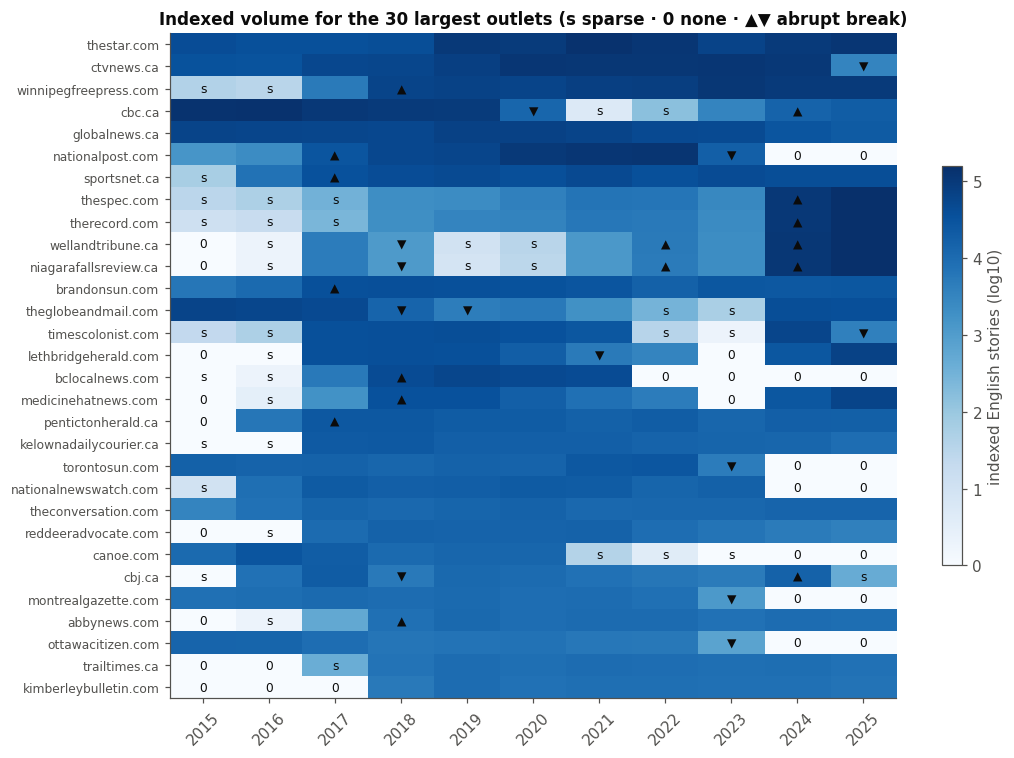

In [15]:
big = pivot.loc[tiers.sort_values("total", ascending=False).head(30).index]
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(np.log10(big.clip(lower=1).values), aspect="auto", cmap="Blues")
ax.set_xticks(range(len(YEARS))); ax.set_xticklabels(YEARS, rotation=45)
ax.set_yticks(range(len(big))); ax.set_yticklabels(big.index, fontsize=8)
flag_lookup = cov_flags.set_index(["source", "year"])["cov_flag"]
for i, src in enumerate(big.index):
    for j, y in enumerate(YEARS):
        f = flag_lookup.get((src, y), "ok")
        if f != "ok":
            ax.text(j, i, {"sparse": "s", "zero": "0", "abrupt_up": "▲", "abrupt_down": "▼"}[f], ha="center", va="center", fontsize=8, color=INK)
ax.grid(False)
cb = plt.colorbar(im, ax=ax, shrink=0.6); cb.set_label("indexed English stories (log10)")
ax.set_title("Indexed volume for the 30 largest outlets (s sparse · 0 none · ▲▼ abrupt break)")
plt.tight_layout(); plt.show()

The table above lists the largest breaks. Where headline-copy counts move by a similar factor to indexed volume, an indexing expansion is the simplest explanation; where they don't, the change may be editorial or noise. Either way these years are flagged in the prepared data (`cov_flag`), and Notebook 3 reports a stable-coverage subset so conclusions don't rest on them.

## 10. Reconciling the archived analysis with the current files

The archived notebooks reported 4,198 tenant and 2,186 landlord "unique" headlines. We reproduce those numbers, see what they excluded, and recompute three of their regex-based statistics on (a) their own subset, (b) all supplied rows, and (c) distinct story families, to see whether the old conclusions depend on the `is_duplicate` filter.

In [16]:
legacy_subset = {"tenant": supplied_t[~supplied_t["is_duplicate"]], "landlord": supplied_l[~supplied_l["is_duplicate"]]}
fam_reps = articles[articles["is_rep_near"] & mentioned]
recon = pd.DataFrame({
    "legacy reported": [LEGACY_REPORTED["tenant_non_duplicate"], LEGACY_REPORTED["landlord_non_duplicate"]],
    "supplied, ~is_duplicate": [len(legacy_subset["tenant"]), len(legacy_subset["landlord"])],
    "all supplied rows": [len(supplied_t), len(supplied_l)],
    "distinct families (near)": [int(fam_reps["family_in_search_tenant"].sum()), int(fam_reps["family_in_search_landlord"].sum())],
}, index=["tenant", "landlord"])
display(recon)

# stories removed outright by the legacy filter: families whose every hierarchy-selected copy carried the flag
sel_rows = articles[articles["selected_by_hierarchy"]]
flagged = sel_rows.groupby("family_id_near")["legacy_is_duplicate_flag"].agg(lambda s: bool(s.fillna(False).astype(bool).all()))
print(f"Families (with a supplied representative) whose every supplied row carried is_duplicate=True: "
      f"{int(flagged.sum()):,} of {len(flagged):,} ({pct(flagged.sum(), len(flagged))}); the old notebooks removed all of these stories.")
yr_loss = (sel_rows[sel_rows["family_id_near"].isin(flagged[flagged].index)].drop_duplicates("family_id_near").groupby("year").size()
           / sel_rows.drop_duplicates("family_id_near").groupby("year").size()).reindex(YEARS).fillna(0)
print("Share of families lost to the legacy filter, by year:", (100 * yr_loss).round(0).astype(int).to_dict())

,legacy reported,"supplied, ~is_duplicate",all supplied rows,distinct families (near)
tenant,4198,4198,4629,4407
landlord,2186,2186,2456,2329


Families (with a supplied representative) whose every supplied row carried is_duplicate=True: 516 of 6,039 (8.5%); the old notebooks removed all of these stories.
Share of families lost to the legacy filter, by year: {2015: 6, 2016: 5, 2017: 7, 2018: 6, 2019: 4, 2020: 9, 2021: 7, 2022: 5, 2023: 8, 2024: 17, 2025: 23}


In [17]:
VICTIM_PATS = [r"\bevict", r"\bdisplac", r"force.*out", r"can.t afford", r"cannot afford", r"struggling.*rent", r"unaffordabl", r"rent burden",
               r"housing insecur", r"nowhere to go", r"renovict", r"above.guideline", r"illegal evict", r"wrongful evict", r"face.*eviction",
               r"fear.*eviction", r"risk.*eviction", r"losing.*home", r"lose.*home"]
AGENT_PATS = [r"tenant.*sue", r"tenant.*win", r"tenant.*fight", r"tenant.*demand", r"tenant.*organiz", r"tenant.*protest", r"renter.*challeng",
              r"renter.*sue", r"rent strike", r"tenant.*rally", r"renter.*fight", r"tenant.*push", r"tenant.*launch", r"tenant.*file", r"tenant.*appeal"]
INSTITUTIONAL_PATS = [r"landlord (group|association|coalition|organiz|lobby|federation|network)", r"(rental|property) (provider|industry|sector|market)",
                      r"(small|independent|mom.and.pop) landlord", r"corporate landlord|reit|real estate investment", r"property manag"]
PRECARIOUS_PATS = [r"vulnerable (tenant|renter)", r"low.income (tenant|renter)", r"senior.*tenant|elderly.*tenant|elderly.*renter",
                   r"single (mother|parent|mom).*rent", r"(tenant|renter).*(nowhere|homeless|unhoused)", r"(fixed|limited) income.*rent",
                   r"precarious.*housing|housing.*precari"]
def legacy_eviction_perspective(title):
    t = title.lower()
    if re.search(r"landlord.{1,25}evict|evict.{1,15}(?:tenant|renter)", t):
        return "landlord_acts"
    if re.search(r"(?:tenant|renter).{1,20}evict|face.{0,8}evict|fear.{0,8}evict|risk.{0,8}evict|avoid.{0,8}evict|fight.{0,8}evict|"
                 r"prevent.{0,8}evict|challeng.{0,8}evict|appea.{0,8}evict|block.{0,8}evict|stop.{0,8}evict", t):
        if re.search(r"fight.{0,8}evict|challeng.{0,8}evict|appea.{0,8}evict|block.{0,8}evict|stop.{0,8}evict|win.{0,8}evict|resist.{0,8}evict", t):
            return "tenant_fights"
        return "tenant_passive"
    return "other"


def any_pat(s, pats):
    rx = re.compile("|".join(f"(?:{p})" for p in pats), re.I)
    return s.str.lower().str.contains(rx)


def legacy_stats(t, l):
    out = {}
    tt = t.assign(y=pd.to_datetime(t["publish_date"]).dt.year)
    v, a = any_pat(tt["title"], VICTIM_PATS), any_pat(tt["title"], AGENT_PATS)
    out["tenant victim:agent ratio, 2020"] = round(v[tt["y"] == 2020].sum() / max(a[tt["y"] == 2020].sum(), 1), 2)
    ev = t[t["title"].str.contains(r"\bevict", case=False)]
    persp = ev["title"].map(legacy_eviction_perspective).value_counts()
    out["tenant corpus: eviction passive:fighting"] = f"{int(persp.get('tenant_passive', 0))}:{int(persp.get('tenant_fights', 0))}"
    out["tenant corpus: landlord-acts share of eviction headlines (%)"] = round(100 * persp.get("landlord_acts", 0) / max(len(ev), 1), 1)
    out["institutional vocabulary, landlord corpus (%)"] = round(100 * any_pat(l["title"], INSTITUTIONAL_PATS).mean(), 1)
    out["precarious vocabulary, tenant corpus (%)"] = round(100 * any_pat(t["title"], PRECARIOUS_PATS).mean(), 1)
    out["n tenant / n landlord"] = f"{len(t):,} / {len(l):,}"
    return out


view_all = (supplied_t, supplied_l)
view_fam = (fam_reps[fam_reps["family_in_search_tenant"]], fam_reps[fam_reps["family_in_search_landlord"]])
legacy_table = pd.DataFrame({
    "legacy subset (~is_duplicate)": legacy_stats(legacy_subset["tenant"], legacy_subset["landlord"]),
    "all supplied rows": legacy_stats(*view_all),
    "distinct story families": legacy_stats(*view_fam),
})
display(legacy_table)

,legacy subset (~is_duplicate),all supplied rows,distinct story families
"tenant victim:agent ratio, 2020",4.48,4.84,4.77
tenant corpus: eviction passive:fighting,144:19,162:19,152:18
tenant corpus: landlord-acts share of eviction headlines (%),26.2,26.8,26.8
"institutional vocabulary, landlord corpus (%)",2.8,2.7,2.7
"precarious vocabulary, tenant corpus (%)",3.0,3.1,3.0
n tenant / n landlord,"4,198 / 2,186","4,629 / 2,456","4,407 / 2,329"


**How to read this.** The first column reproduces the archived notebooks' regex statistics from their own subset. The other columns show the same code on all supplied rows and on distinct families. Differences between columns are the effect of the `is_duplicate` filter and of counting syndicated copies; the later notebooks replace these crude regexes entirely with group-attributed measures. While reading the archive we also noticed that its summary boxes contained hand-typed figures (for example an eviction "39% vs 20%" and a "10x" passive-to-fighting ratio) that do not match the numbers its own cells printed (26% vs 44% and about 7.6:1), which is one reason every number in the new notebooks is generated from results.

## 11. Save the prepared dataset

One table, one row per headline copy. Distinct-story analysis uses `is_rep_near` (or `is_rep_exact`) rows; outlet-level analysis uses all rows. Coverage context is attached so later notebooks need no extra joins.

In [18]:
cov_attach = cov_flags[["source", "year", "indexed_n", "cov_flag"]].rename(columns={"source": "media_name", "indexed_n": "cov_indexed_n"})
prepared = (articles.merge(cov_attach, on=["media_name", "year"], how="left")
            .merge(tiers[["tier"]].rename(columns={"tier": "source_tier"}), left_on="media_name", right_index=True, how="left"))
COLS = ["id", "title", "title_norm", "url", "publish_date", "year", "media_name", "language",
        "in_search_tenant", "in_search_landlord", "in_supplied_tenant", "in_supplied_landlord", "selected_by_hierarchy",
        "legacy_is_duplicate_flag", "publication_copy_source",
        "mentions_tenant", "mentions_landlord", "mention_group", "institution_name_in_title", "relevance",
        "family_id_exact", "family_id_near", "family_n_copies_exact", "family_n_copies_near", "family_n_outlets_near",
        "family_in_search_tenant", "family_in_search_landlord", "is_rep_exact", "is_rep_near",
        "cov_indexed_n", "cov_flag", "source_tier"]
prepared = prepared[COLS].sort_values(["publish_date", "id"]).reset_index(drop=True)
PREPARED_PATH.parent.mkdir(parents=True, exist_ok=True)
prepared.to_csv(PREPARED_PATH, index=False)

check = pd.read_csv(PREPARED_PATH)
print(f"Saved {len(check):,} rows × {check.shape[1]} columns → {PREPARED_PATH}")
print("IDs unique:", bool(check["id"].is_unique), "| one representative per near family:",
      bool((check.groupby("family_id_near")["is_rep_near"].sum() == 1).all()),
      "| one representative per exact family:", bool((check.groupby("family_id_exact")["is_rep_exact"].sum() == 1).all()))

Saved 7,726 rows × 32 columns → ../../data/headlines/prepared/headlines_prepared.csv
IDs unique: True | one representative per near family: True | one representative per exact family: True


## 12. What this notebook established, and the limits

The summary below is generated from the tables above.

In [19]:
d = check
main = d[d["is_rep_near"] & d["mention_group"].isin(["tenant", "landlord", "both"])]
lines = [
    f"- **Rows.** {len(d):,} headline copies in {d['family_id_near'].nunique():,} near-duplicate story families; "
    f"{len(main):,} distinct stories mention tenants and/or landlords "
    f"({(main['mention_group'] == 'tenant').sum():,} tenant-only, {(main['mention_group'] == 'landlord').sum():,} landlord-only, {(main['mention_group'] == 'both').sum():,} both).",
    f"- **Provenance.** Original downloads {'reproduce the supplied files exactly, so publication copies were recovered' if HAS_PUBLICATION_COPIES else 'are unavailable, so only hierarchy-selected representatives exist and outlet-level publication rates cannot be computed'}; "
    f"{int((~d['selected_by_hierarchy']).sum()):,} recovered copies were discarded by the old hierarchy step.",
    f"- **Relevance.** {pct((main['relevance'] == 'commercial').sum(), len(main))} of distinct stories carry commercial-only cues and {pct((main['relevance'] == 'residential').sum(), len(main))} explicit residential cues; the rest are mixed or unclear.",
    f"- **Concentration.** The five largest outlets supply {pct(d['media_name'].value_counts().head(5).sum(), len(d))} of all copies.",
    f"- **Coverage.** {int(cov_flags['cov_flag'].isin(['abrupt_up', 'abrupt_down']).sum())} source-years show abrupt volume breaks and {int((cov_flags['cov_flag'] == 'sparse').sum())} are sparse; {pct((d['cov_flag'].isin(['abrupt_up', 'abrupt_down', 'sparse', 'zero'])).sum(), len(d))} of headline copies fall in a flagged source-year.",
    f"- **Coverage API.** {'No requests were needed: all source-year counts were present.' if len(missing_cells) == 0 else f'{len(missing_cells)} source-year counts were missing.'}",
]
display(Markdown("\n".join(lines)))

- **Rows.** 7,726 headline copies in 6,039 near-duplicate story families; 5,939 distinct stories mention tenants and/or landlords (3,590 tenant-only, 1,528 landlord-only, 821 both).
- **Provenance.** Original downloads reproduce the supplied files exactly, so publication copies were recovered; 1,505 recovered copies were discarded by the old hierarchy step.
- **Relevance.** 3.0% of distinct stories carry commercial-only cues and 63.7% explicit residential cues; the rest are mixed or unclear.
- **Concentration.** The five largest outlets supply 53.1% of all copies.
- **Coverage.** 52 source-years show abrupt volume breaks and 362 are sparse; 8.6% of headline copies fall in a flagged source-year.
- **Coverage API.** No requests were needed: all source-year counts were present.

**Limits to carry forward.** Everything here describes *indexed English-language headlines from one MediaCloud collection*. French-language outlets are absent by construction; indexing changes over time; the keyword frame (tenant/renter/landlord in the title) excludes headlines about the same people that use other words; and a headline is not an article. Next: Notebook 2 measures how each group is portrayed in these headlines.